# Fase 2 y 3 - Modelado MCO (OLS) y Diagnóstico de Supuestos

**Objetivo**: Estimar el modelo de Regresión Lineal Múltiple por MCO para explicar la severidad de síntomas de TDAH en adultos (`ASRS`), evaluar su significancia global e individual y diagnostivar los supuestos clásicos sobre los residuales.

**Dataset**: `../data/processed/hyperaktiv_arc_clean.csv` ($n_{efectivo}=69$).

**Fecha**: 20 de Noviembre del 2026.


## 1. Configuración y carga del dataset de modelado

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display


In [2]:
DATA_PATH = Path("../data/processed/hyperaktiv_arc_clean.csv")

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

TAB_DIR = Path("../reports/tables")
TAB_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
TARGET_COL = "ASRS"
FEATURE_COLS = ["WURS", "General TScore Commissions", "HADS_A"]

In [4]:
df = pd.read_csv(DATA_PATH)
df_model = df[[TARGET_COL] + FEATURE_COLS].dropna().copy()

X = df_model[FEATURE_COLS]
y = df_model[TARGET_COL]

n_effective = len(df_model)

## 2. Planteamiento formal del modelo MCO

**Ecuación Poblacional:**
$$\text{ASRS}_i = \beta_0 + \beta_1 \text{WURS}_i + \beta_2 \text{Commissions}_i + \beta_3 \text{HADS\_A}_i + \epsilon_i$$

**Ecuacion estimada:**
$$\hat{\text{ASRS}}_i = \hat{\beta_0} + \hat{\beta_1} \text{WURS}_i + \hat{\beta_2} \text{Commissions}_i + \hat{\beta_3} \text{HADS\_A}_i$$

|Símbolo|Variable|Descripción clínica|Escala / Unidades|
|---|---|---|---|
|$Y$|ASRS|Severidad autorreportada de síntomas de TDAH en adultos|(puntaje continuo, 0–72)|
|$X_1$|WURS|Wender Utah Rating Scale, síntomas retrospectivos de TDAH en la infancia|(puntaje continuo, 0–100)|
|$X_2$|General TScore Commissions|Errores de comisión en la prueba CPT-II, indicador objetivo de impulsividad/inhibición de respuesta|(puntaje T, media 50, DE 10)|
|$X_3$|HADS_A|Subescala de ansiedad de la Hospital Anxiety and Depression Scale| (puntaje continuo, 0–21)|

## 3. Ajuste del modelo MCO y evaluación estadística

### 3.1 Estimación por Mínimos Cuadrados Ordinarios (`statsmodels`)

In [5]:
# Agregando constante a la matriz de diseño
X_const = sm.add_constant(X)

# Ajustando el modelo con statsmodels.api.OLS().fit()
ols_model = sm.OLS(y, X_const).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   ASRS   R-squared:                       0.534
Model:                            OLS   Adj. R-squared:                  0.513
Method:                 Least Squares   F-statistic:                     24.84
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           8.00e-11
Time:                        16:03:46   Log-Likelihood:                -254.04
No. Observations:                  69   AIC:                             516.1
Df Residuals:                      65   BIC:                             525.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

### 3.2 Exportación de tabla de coeficientes y métricas globales

In [6]:
conf_int_df = ols_model.conf_int(alpha=0.05)

coef_df = pd.DataFrame({
    "term": conf_int_df.index,
    "coef": ols_model.params,
    "std_err": ols_model.bse,
    "t_stat": ols_model.tvalues,
    "p_value": ols_model.pvalues,
    "ci_lower": conf_int_df[0],
    "ci_upper": conf_int_df[1]
}).reset_index(drop=True)

coef_df = coef_df.round(4)
coef_df

,term,coef,std_err,t_stat,p_value,ci_lower,ci_upper
0,const,7.6350,6.1095,1.2497,0.2159,-4.5666,19.8365
1,WURS,0.3678,0.0736,4.9957,0.0000,0.2208,0.5149
2,General TScore Commissions,0.3079,0.1162,2.6507,0.0101,0.0759,0.5399
3,HADS_A,0.1273,0.2833,0.4492,0.6547,-0.4385,0.6931


In [7]:
coef_df.to_csv(TAB_DIR / "ols_coefficients.csv", index=False)

In [10]:
metrics_df = pd.DataFrame([{
    "n_obs": int(ols_model.nobs),
    "r2": round(ols_model.rsquared, 4),
    "r2_adj": round(ols_model.rsquared_adj, 4),
    "f_stat": round(ols_model.fvalue, 4),
    "f_pvalue": float(ols_model.f_pvalue),
    "rmse": round(float(np.sqrt(ols_model.mse_resid)), 4),
    "aic": round(ols_model.aic, 2),
    "bic": round(ols_model.bic, 2),
}])


display(metrics_df)
metrics_df.to_csv(TAB_DIR / "ols_summary_metrics.csv", index=False)

,n_obs,r2,r2_adj,f_stat,f_pvalue,rmse,aic,bic
0,69,0.5341,0.5126,24.8355,7.999573e-11,9.9015,516.08,525.02


### 3.3 Interpretación estadística y clínica de parámetros

#### 1. Ecuación de regresión estimada (Rúbrica 2a)

Sustituyendo los coeficientes estimados por MCO ($n = 69$), la ecuación del modelo queda expresada como:

$$\widehat{\text{ASRS}}_i = 7.6350 + 0.3678\,\text{WURS}_i + 0.3079\,\text{Commissions}_i + 0.1273\,\text{HADS\_A}_i$$

---

#### 2. Interpretación teórica y práctica de los parámetros (*ceteris paribus* — Rúbrica 2b)

- **Intercepto ($\hat{\beta}_0 = 7.6350$, $EE = 6.1095$, $p = 0.2159$):** representa el puntaje esperado de `ASRS` cuando `WURS = 0`, `General TScore Commissions = 0` y `HADS_A = 0`. Su interpretación es **estrictamente matemática** y no clínica, dado que un puntaje $T$ de comisiones igual a 0 se ubica a 5 desviaciones estándar por debajo de la media poblacional ($T = 50$), fuera del dominio observable en pacientes reales. Además, no es estadísticamente distinto de cero ($p > 0.05$).
- **Síntomas en la infancia — `WURS` ($\hat{\beta}_1 = 0.3678$, $EE = 0.0736$, $p < 0.0001$, IC 95 %: $[0.2208, 0.5149]$):** manteniendo constantes el desempeño en el CPT-II (`Commissions`) y el nivel de ansiedad (`HADS_A`), por cada incremento de **1 punto** en la escala retrospectiva `WURS`, la severidad actual de síntomas de TDAH en el adulto (`ASRS`) aumenta en promedio **0.3678 puntos** (es decir, $\approx 3.68$ puntos adicionales en `ASRS` por cada 10 puntos de `WURS`). Es el predictor con mayor peso explicativo, consistente con la naturaleza neuroevolutiva del TDAH.
- **Impulsividad objetiva — `General TScore Commissions` ($\hat{\beta}_2 = 0.3079$, $EE = 0.1162$, $p = 0.0101$, IC 95 %: $[0.0759, 0.5399]$):** manteniendo constantes `WURS` y `HADS_A`, por cada incremento de **1 unidad en el puntaje $T$** de errores de comisión en el CPT-II (respuestas impulsivas ante estímulos no-objetivo), el puntaje `ASRS` aumenta en promedio **0.3079 puntos** ($\approx 3.08$ puntos en `ASRS` por cada desviación estándar de 10 puntos $T$). Confirma que el déficit objetivo de inhibición motora aporta información independiente al autorreporte histórico.
- **Ansiedad comórbida — `HADS_A` ($\hat{\beta}_3 = 0.1273$, $EE = 0.2833$, $p = 0.6547$, IC 95 %: $[-0.4385, 0.6931]$):** manteniendo constantes `WURS` y `Commissions`, cada punto adicional en la subescala de ansiedad se asocia con un cambio promedio de **0.1273 puntos** en `ASRS`, pero este efecto **no es estadísticamente significativo** (su intervalo de confianza al 95 % cruza el cero). Clínicamente esto revela un efecto de confusión/colinealidad moderada: aunque `HADS_A` mostraba correlación bivariada significativa con `ASRS` ($r = 0.304$), al controlar por la carga histórica de TDAH en la infancia (`WURS`, con la cual correlaciona $r = 0.41$), la ansiedad deja de tener un efecto lineal directo e independiente sobre `ASRS`.

---

#### 3. Evaluación global e individual del modelo (Rúbrica 4a y 4b)

- **Bondad de ajuste ($R^2$ y $R^2_{\text{ajustado}}$ — Rúbrica 4a):** el coeficiente de determinación es **$R^2 = 0.5341$** y el ajustado por grados de libertad es **$R^2_{\text{adj}} = 0.5126$**, con un error cuadrático medio residual de **$\text{RMSE} = 9.9015$** puntos en la escala `ASRS` (0–72). Esto indica que el modelo explica el **53.41 %** de la variabilidad total de la severidad de síntomas de TDAH en adultos (51.26 % penalizando por los $k = 3$ predictores), un desempeño sólido para escalas clínicas y neuropsicológicas.
- **Significancia global — Prueba $F$ (Rúbrica 4b):** para contrastar $H_0: \beta_1 = \beta_2 = \beta_3 = 0$ frente a $H_1: \text{al menos un } \beta_j \neq 0$, se obtiene **$F(3, 65) = 24.8355$** con **$p = 8.00 \times 10^{-11} < 0.001$**. Se rechaza contundentemente $H_0$, concluyendo que el conjunto de regresores explica una proporción altamente significativa de la varianza de `ASRS`.
- **Significancia individual — Pruebas $t$ (Rúbrica 4b):** al nivel de significancia $\alpha = 0.05$ ($gl = 65$), resultan estadísticamente significativos **`WURS`** ($t = 4.9957, p < 0.0001$) y **`General TScore Commissions`** ($t = 2.6507, p = 0.0101$), mientras que **`HADS_A`** ($t = 0.4492, p = 0.6547$) no aporta significancia marginal una vez incluidos los dos primeros predictores.

## 4. Evaluación visual del ajuste: Valores reales vs. predichos

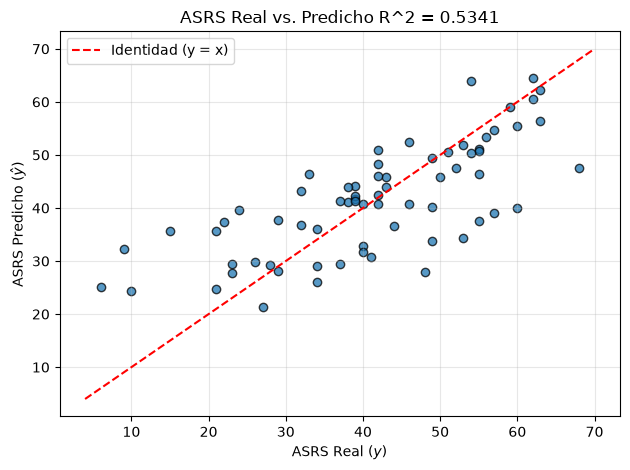

In [22]:
y_pred = ols_model.fittedvalues

plt.scatter(y, y_pred, alpha=0.75, edgecolor="k")

axis_min = min(y.min(), y_pred.min()) - 2
axis_max = max(y.max(), y_pred.max()) + 2

plt.plot([axis_min, axis_max], [axis_min, axis_max], color="red", linestyle="--", label="Identidad (y = x)")

plt.title(f"ASRS Real vs. Predicho R^2 = {ols_model.rsquared:.4f}")
plt.xlabel("ASRS Real ($y$)")
plt.ylabel("ASRS Predicho ($\\hat y$)")

plt.legend()
plt.tight_layout()
plt.grid(True, alpha=0.3)

plt.savefig(FIG_DIR / "ols_real_vs_predicho.png", dpi=150)

## 5. Diagnóstico de supuestos de los residuales

### 5.1 Extracción de valores ajustados, residuales y distancia de Cook

In [23]:
residuals = ols_model.resid
influence = ols_model.get_influence()
std_residuals = influence.resid_studentized_internal
cooks_d = influence.cooks_distance[0]
cooks_threshold = 4 / n_effective

### 5.2 Panel gráfico de diagnóstico de residuales

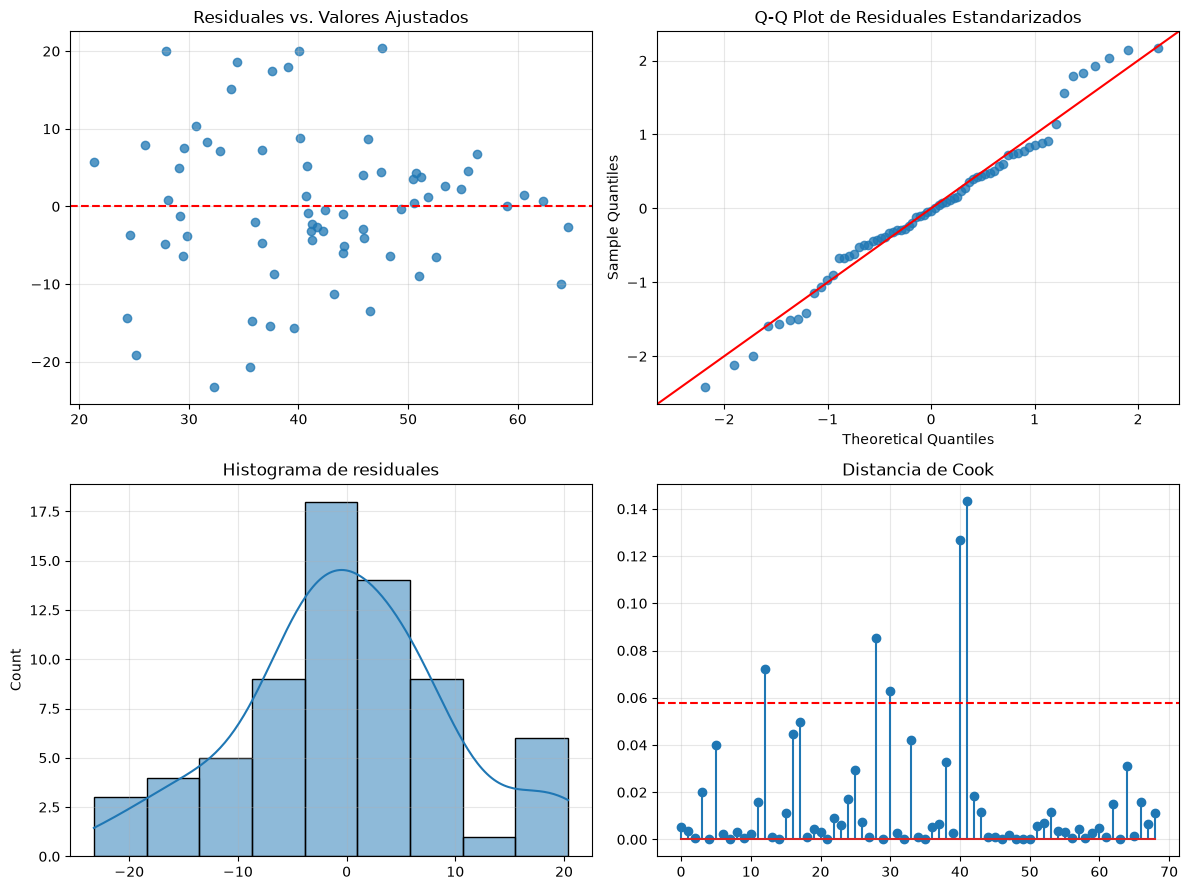

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].set_title("Residuales vs. Valores Ajustados")
axes[0, 0].scatter(y_pred, residuals, alpha = 0.75)
axes[0, 0].axhline(0, color="red", linestyle="--")

axes[0, 1].set_title("Q-Q Plot de Residuales Estandarizados")
sm.qqplot(std_residuals, line="45", ax=axes[0, 1], alpha=0.75)

axes[1, 0].set_title("Histograma de residuales")
sns.histplot(residuals, kde=True, ax=axes[1, 0])

axes[1, 1].set_title("Distancia de Cook")
axes[1, 1].stem(range(n_effective), cooks_d)
axes[1, 1].axhline(cooks_threshold, color="red", linestyle="--", label=f"4/n = {cooks_threshold:.3f}")


axes[0, 0].grid(True, alpha=0.3)
axes[0, 1].grid(True, alpha=0.3)
axes[1, 0].grid(True, alpha=0.3)
axes[1, 1].grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(FIG_DIR / "ols_residual_diagnostics.png", dpi=150)

### 5.3 Pruebas estadísticas formales sobre los residuales

In [49]:
from scipy.stats import shapiro
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

# Cálculo de normalidad (Shapiro-Wilk)
shapiro_stat, shapiro_p = shapiro(residuals)

# Homocedasticidad (Breusch-Pagan)
bp_stat, bp_p, f_bp, f_bp_p = het_breuschpagan(residuals, X_const)

# Conteo de puntos con Cook > 4/2 y > 1
n_influencial_4n = int((cooks_d > cooks_threshold).sum())
n_influencial_1 = int((cooks_d > 1.0).sum())

diagnostics_df = pd.DataFrame([{
    "shapiro_stat": shapiro_stat,
    "shapiro_p": shapiro_p,
    "bp_stat": bp_stat,
    "bp_p": bp_p,
    "f_bp": f_bp,
    "f_bp_p": f_bp_p,
    "n_influencial_4n": n_influencial_4n,
    "n_influencial_1": n_influencial_1
}])

display(diagnostics_df)
diagnostics_df.to_csv(TAB_DIR / "ols_diagnostics.csv", index=False)

,shapiro_stat,shapiro_p,bp_stat,bp_p,f_bp,f_bp_p,n_influencial_4n,n_influencial_1
0,0.978006,0.263442,6.77047,0.079585,2.357298,0.079818,5,0


### 5.4 Conclusión del diagnóstico y decisión sobre transformaciones

#### 1. Evaluación visual del ajuste: Valores reales vs. predichos (Rúbrica 4c)
- La gráfica de `ASRS` real ($y$) frente al valor ajustado ($\hat{y}$) muestra una alineación positiva y consistente en torno a la recta identidad ($y = x$), reflejando el $R^2 = 0.5341$ ($R^2_{\text{adj}} = 0.5126$).
- Como es habitual en modelos de regresión por MCO con dispersión moderada ($\text{RMSE} = 9.9015$), las predicciones tienden a contraerse ligeramente hacia la media: los pacientes con puntajes clínicos extremadamente bajos ($y < 15$) son levemente sobreestimados, mientras que los puntajes cercanos al techo de la escala ($y > 60$) presentan una ligera subestimación, sin evidenciar curvaturas sistemáticas.

---

#### 2. Verificación de los supuestos clásicos sobre los residuales
- **Linealidad y media cero:** en el gráfico de residuales vs. valores ajustados, la nube de puntos se distribuye aleatoriamente alrededor de la línea horizontal $e_i = 0$, sin patrones parabólicos ni asimetrías estructurales.
- **Normalidad de los errores ($\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$):** el Q-Q plot de residuales estandarizados sigue de forma muy estrecha la recta de $45^\circ$ y el histograma presenta una silueta simétrica y acampanada. La prueba formal de **Shapiro-Wilk** arroja **$W = 0.9780$ ($p = 0.2634 > 0.05$)** —consistente con las pruebas Omnibus ($p = 0.885$) y Jarque-Bera ($p = 0.991$) del resumen OLS—, por lo que **no se rechaza $H_0$** y se confirma la normalidad de los residuales. Esto valida plenamente las pruebas $t$, la prueba $F$ y los intervalos de confianza.
- **Homocedasticidad (varianza constante):** la prueba de **Breusch-Pagan** arroja **$\text{LM} = 6.7705$ ($p = 0.0796 > 0.05$)** y **$F = 2.3573$ ($p = 0.0798 > 0.05$)**. Al nivel de significancia estándar $\alpha = 0.05$, **no se rechaza la hipótesis nula de homocedasticidad**; sin embargo, dado que el valor $p \approx 0.08$ se encuentra relativamente próximo al umbral del 5 %, se justifica explorar en el Notebook 04 si alguna transformación funcional estabiliza aún más la varianza.
- **Independencia de los errores:** el estadístico de **Durbin-Watson** obtenido en el ajuste es **$\text{DW} = 2.174$** (muy cercano al valor ideal de $2.0$), confirmando ausencia de autocorrelación residual.
- **Observaciones influyentes (Distancia de Cook):** aunque **5 observaciones** superan el umbral preventivo conservador $4/n = 0.0580$, **ninguna observación ($0$ casos)** rebasa el umbral crítico $D_i > 1.0$. Por tanto, el ajuste MCO es estable y no está dominado por valores atípicos extremos.

---

#### 3. Decisión metodológica para la Fase 3/4 (Notebook 04 — Rúbrica 3a)
1. El **modelo lineal base en escala original** cumple satisfactoriamente los supuestos clásicos de Gauss-Markov y normalidad al nivel $\alpha = 0.05$.
2. No obstante, para cubrir rigurosamente la **Rúbrica 3a** y atender tanto el valor $p$ marginal de Breusch-Pagan ($p = 0.0796$) como la no significancia individual de `HADS_A` ($p = 0.6547$), en el **Notebook 04 (`04_transformations_and_forecasting.ipynb`)** se evaluarán transformaciones matemáticas (p. ej., $\ln(\text{ASRS})$, $\sqrt{\text{ASRS}}$ y transformaciones en predictores) junto con su **reversión analítica a la escala original**, comparando su desempeño frente al modelo base antes de calcular las estimaciones puntuales para los perfiles clínicos (**Rúbrica 5a**).